In [28]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
df = pd.read_csv(r"C:\Users\HP\Downloads\Mall_Customers.csv")

In [30]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [22]:
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
X = StandardScaler().fit_transform(X)


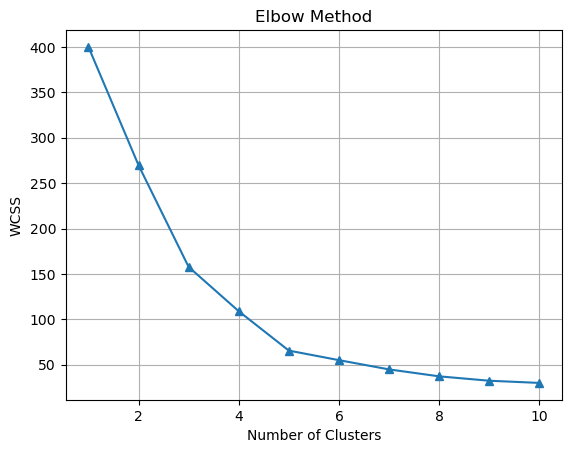

In [25]:

wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker="^")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid()
plt.show()


Number of Clusters: 5


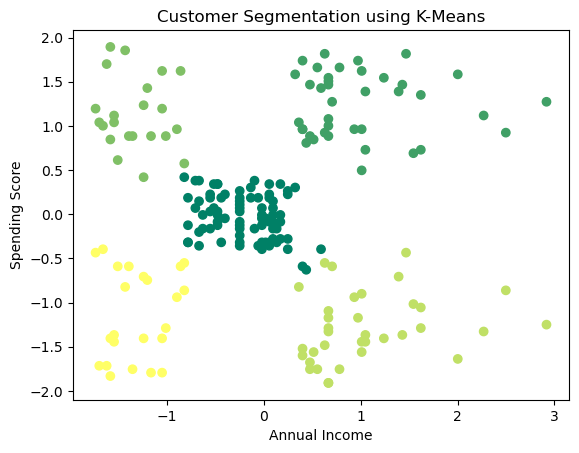

In [32]:
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X)


print("\nNumber of Clusters:", df["Cluster"].nunique())

plt.scatter(X[:, 0], X[:, 1], c=df["Cluster"], cmap="summer")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using K-Means")
plt.show()